<a href="https://colab.research.google.com/github/Vithya-Sree/Airline-Flight-Delays-Analysis/blob/main/Root_Cause_Analysis_of_U_S_Aviation_Bottlenecks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Root Cause Analysis of U.S. Aviation Bottlenecks using Python (2020 - 2026)
(Airline Arrival Delays Analysis)

Project Objectives

1. Analyze flight delay trends by month and year
2. Compare flight delays and delay rates across airports and airlines
3. Identify the Main Causes of Flight Delays and Their Proportional Share
4. Analyze Flight Delays, Cancellations, and Diversions
5. Compare Total Delay Duration by Cause
6. Evaluate Average Delay Duration per Delayed Flight

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pandas as pd
url = "https://raw.githubusercontent.com/Vithya-Sree/Airline-Flight-Delays-Analysis/refs/heads/main/Airline_Delay_Cause.csv"

df = pd.read_csv(url)

df.head()

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2026,7,9E,Endeavor Air Inc.,ATL,"Atlanta, GA: Hartsfield-Jackson Atlanta Intern...",3025.0,928.0,182.23,53.49,...,1.0,475.59,91.0,29.0,96739.0,24403.0,6656.0,19423.0,18.0,46239.0
1,2026,7,9E,Endeavor Air Inc.,AUS,"Austin, TX: Austin - Bergstrom International",88.0,15.0,7.13,0.00,...,0.0,1.10,0.0,0.0,1009.0,454.0,0.0,423.0,0.0,132.0
2,2026,7,9E,Endeavor Air Inc.,BNA,"Nashville, TN: Nashville International",271.0,73.0,21.92,1.86,...,0.0,29.47,37.0,3.0,6255.0,1642.0,162.0,1790.0,0.0,2661.0
3,2026,7,9E,Endeavor Air Inc.,CLT,"Charlotte, NC: Charlotte Douglas International",225.0,54.0,19.80,0.00,...,0.0,15.10,31.0,1.0,3867.0,1685.0,0.0,936.0,0.0,1246.0
4,2026,7,9E,Endeavor Air Inc.,DCA,"Washington, DC: Ronald Reagan Washington National",173.0,68.0,9.29,1.06,...,0.0,18.91,15.0,1.0,6397.0,1324.0,103.0,2692.0,0.0,2278.0


arr_flights: Total number of arriving flights.



arr_del15: Number of arriving flights delayed by 15 minutes or more.



arr_cancelled: Number of cancelled flights.



arr_diverted: Number of flights diverted to another airport.



carrier_ct, weather_ct, etc.: Estimated number of delayed flights attributed to each cause.



arr_delay: Total arrival delay duration, generally measured in minutes.



carrier_delay, weather_delay, etc.: Delay duration attributed to each cause, generally in minutes.

### Initial EDA (Exploratory Data Analysis)

In [3]:
df.tail()

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
28724,2020,1,ZW,Air Wisconsin Airlines Corp,BNA,"Nashville, TN: Nashville International",59.0,8.0,3.12,0.00,...,0.0,3.84,1.0,0.0,346.0,124.0,0.0,48.0,0.0,174.0
28725,2020,1,ZW,Air Wisconsin Airlines Corp,DEN,"Denver, CO: Denver International",74.0,19.0,8.48,2.03,...,0.0,4.39,0.0,2.0,1500.0,639.0,239.0,174.0,0.0,448.0
28726,2020,1,ZW,Air Wisconsin Airlines Corp,IAD,"Washington, DC: Washington Dulles International",1688.0,248.0,66.13,5.55,...,0.0,83.91,10.0,1.0,19747.0,6617.0,1490.0,2612.0,0.0,9028.0
28727,2020,1,ZW,Air Wisconsin Airlines Corp,LGA,"New York, NY: LaGuardia",5.0,0.0,0.00,0.00,...,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
28728,2020,1,ZW,Air Wisconsin Airlines Corp,ORD,"Chicago, IL: Chicago O'Hare International",2678.0,450.0,102.09,10.97,...,0.0,183.64,128.0,7.0,39037.0,10200.0,686.0,9555.0,0.0,18596.0


In [4]:
print(df.shape)

(28729, 21)


In [5]:
print(df.columns)

Index(['year', 'month', 'carrier', 'carrier_name', 'airport', 'airport_name',
       'arr_flights', 'arr_del15', 'carrier_ct', 'weather_ct', 'nas_ct',
       'security_ct', 'late_aircraft_ct', 'arr_cancelled', 'arr_diverted',
       'arr_delay', 'carrier_delay', 'weather_delay', 'nas_delay',
       'security_delay', 'late_aircraft_delay'],
      dtype='object')


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28729 entries, 0 to 28728
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   year                 28729 non-null  int64  
 1   month                28729 non-null  int64  
 2   carrier              28729 non-null  object 
 3   carrier_name         28729 non-null  object 
 4   airport              28729 non-null  object 
 5   airport_name         28729 non-null  object 
 6   arr_flights          28718 non-null  float64
 7   arr_del15            28681 non-null  float64
 8   carrier_ct           28718 non-null  float64
 9   weather_ct           28718 non-null  float64
 10  nas_ct               28718 non-null  float64
 11  security_ct          28718 non-null  float64
 12  late_aircraft_ct     28718 non-null  float64
 13  arr_cancelled        28718 non-null  float64
 14  arr_diverted         28718 non-null  float64
 15  arr_delay            28718 non-null 

In [7]:
df.describe()

,year,month,arr_flights,arr_del15,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
count,28729.000000,28729.000000,28718.000000,28681.000000,28718.000000,28718.000000,28718.000000,28718.000000,28718.000000,28718.000000,28718.000000,28718.000000,28718.00000,28718.00000,28718.000000,28718.000000,28718.00000
mean,2022.790804,6.256361,1005.660526,190.609811,59.946502,7.069861,57.458801,0.513751,65.373776,22.670137,2.511004,14045.972387,4922.46396,799.26701,2968.670903,24.866251,5330.34609
std,1.890971,3.444163,1788.575861,350.043343,105.221607,17.753342,112.647270,1.348504,141.504860,92.626030,7.680164,28985.037664,10409.88223,2262.36130,6757.055405,79.014638,12198.76905
min,2020.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.00000
25%,2021.000000,3.000000,91.000000,15.000000,5.320000,0.000000,3.750000,0.000000,2.962500,0.000000,0.000000,860.250000,308.00000,0.00000,148.000000,0.000000,182.00000
50%,2023.000000,6.000000,351.000000,64.000000,21.595000,1.500000,17.300000,0.000000,16.350000,3.000000,0.000000,3985.000000,1413.00000,113.00000,748.000000,0.000000,1191.00000
75%,2024.000000,9.000000,1059.000000,209.000000,66.520000,6.017500,61.937500,0.330000,61.960000,14.000000,2.000000,14499.750000,4955.75000,605.00000,2902.000000,14.000000,4928.25000
max,2026.000000,12.000000,21854.000000,5544.000000,1886.580000,343.380000,1737.450000,29.840000,2588.130000,4951.000000,232.000000,648300.000000,321792.00000,64550.00000,182823.000000,3760.000000,279153.00000


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

,0
year,0
month,0
carrier,0
carrier_name,0
airport,0
airport_name,0
arr_flights,11
arr_del15,48
carrier_ct,11
weather_ct,11


Handle the missing values

In [10]:
# Create a copy of the original dataset
df_clean = df.copy()

In [11]:
# Display rows where arr_flights is missing
df_clean[df_clean["arr_flights"].isnull()]

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
10130,2024,3,F9,Frontier Airlines,IAD,"Washington, DC: Washington Dulles International",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17180,2022,8,G7,GoJet Airlines LLC d/b/a United Express,MSP,"Minneapolis, MN: Minneapolis-St Paul Internati...",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21008,2021,10,F9,Frontier Airlines,LAX,"Los Angeles, CA: Los Angeles International",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21938,2021,7,G7,GoJet Airlines LLC d/b/a United Express,BNA,"Nashville, TN: Nashville International",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
22505,2021,6,PT,Piedmont Airlines,DCA,"Washington, DC: Ronald Reagan Washington National",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25377,2020,10,OO,SkyWest Airlines Inc.,BOS,"Boston, MA: Logan International",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25380,2020,10,OO,SkyWest Airlines Inc.,DCA,"Washington, DC: Ronald Reagan Washington National",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25468,2020,10,YV,Mesa Airlines Inc.,FLL,"Fort Lauderdale, FL: Fort Lauderdale-Hollywood...",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25475,2020,10,YV,Mesa Airlines Inc.,TPA,"Tampa, FL: Tampa International",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
27191,2020,4,UA,United Air Lines Network,CLT,"Charlotte, NC: Charlotte Douglas International",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
# Remove rows where arr_flights is missing
df_clean = df_clean.dropna(subset=["arr_flights"])

In [13]:
# Count missing values in each column
print(df_clean.isnull().sum())

year                    0
month                   0
carrier                 0
carrier_name            0
airport                 0
airport_name            0
arr_flights             0
arr_del15              37
carrier_ct              0
weather_ct              0
nas_ct                  0
security_ct             0
late_aircraft_ct        0
arr_cancelled           0
arr_diverted            0
arr_delay               0
carrier_delay           0
weather_delay           0
nas_delay               0
security_delay          0
late_aircraft_delay     0
dtype: int64


In [14]:
# Display rows where arr_del15 is missing
df_clean[df_clean["arr_del15"].isnull()]

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
6984,2024,12,C5,CommuteAir LLC dba CommuteAir,AUS,"Austin, TX: Austin - Bergstrom International",1.0,NaN,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
13488,2023,6,G7,GoJet Airlines LLC d/b/a United Express,CLT,"Charlotte, NC: Charlotte Douglas International",1.0,NaN,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
16522,2022,10,OO,SkyWest Airlines Inc.,PHL,"Philadelphia, PA: Philadelphia International",1.0,NaN,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19847,2022,1,OO,SkyWest Airlines Inc.,BOS,"Boston, MA: Logan International",7.0,NaN,0.0,0.0,...,0.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19943,2022,1,YV,Mesa Airlines Inc.,BOS,"Boston, MA: Logan International",2.0,NaN,0.0,0.0,...,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26971,2020,5,G4,Allegiant Air,BOS,"Boston, MA: Logan International",28.0,NaN,0.0,0.0,...,0.0,0.0,28.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26979,2020,5,G4,Allegiant Air,SAN,"San Diego, CA: San Diego International",17.0,NaN,0.0,0.0,...,0.0,0.0,17.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26987,2020,5,MQ,Envoy Air,BNA,"Nashville, TN: Nashville International",1.0,NaN,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26989,2020,5,MQ,Envoy Air,DCA,"Washington, DC: Ronald Reagan Washington National",2.0,NaN,0.0,0.0,...,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
27150,2020,4,OO,SkyWest Airlines Inc.,BWI,"Baltimore, MD: Baltimore/Washington Internatio...",6.0,NaN,0.0,0.0,...,0.0,0.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [15]:
# Check the relevant columns in rows with missing arr_del15
df_clean.loc[
    df_clean["arr_del15"].isnull(),
    [
        "year",
        "month",
        "carrier",
        "airport",
        "arr_flights",
        "arr_del15",
        "carrier_ct",
        "arr_cancelled",
        "arr_diverted",
        "arr_delay"
    ]
]

,year,month,carrier,airport,arr_flights,arr_del15,carrier_ct,arr_cancelled,arr_diverted,arr_delay
6984,2024,12,C5,AUS,1.0,NaN,0.0,1.0,0.0,0.0
13488,2023,6,G7,CLT,1.0,NaN,0.0,1.0,0.0,0.0
16522,2022,10,OO,PHL,1.0,NaN,0.0,1.0,0.0,0.0
19847,2022,1,OO,BOS,7.0,NaN,0.0,7.0,0.0,0.0
19943,2022,1,YV,BOS,2.0,NaN,0.0,2.0,0.0,0.0
26971,2020,5,G4,BOS,28.0,NaN,0.0,28.0,0.0,0.0
26979,2020,5,G4,SAN,17.0,NaN,0.0,17.0,0.0,0.0
26987,2020,5,MQ,BNA,1.0,NaN,0.0,1.0,0.0,0.0
26989,2020,5,MQ,DCA,2.0,NaN,0.0,2.0,0.0,0.0
27150,2020,4,OO,BWI,6.0,NaN,0.0,6.0,0.0,0.0


Verify whether all 37 rows have every flight cancelled.

In [16]:
# Fill missing arr_del15 values with 0
df_clean.loc[
    df_clean["arr_del15"].isnull(),
    "arr_del15"
] = 0

In [17]:
print(df_clean.isnull().sum())

year                   0
month                  0
carrier                0
carrier_name           0
airport                0
airport_name           0
arr_flights            0
arr_del15              0
carrier_ct             0
weather_ct             0
nas_ct                 0
security_ct            0
late_aircraft_ct       0
arr_cancelled          0
arr_diverted           0
arr_delay              0
carrier_delay          0
weather_delay          0
nas_delay              0
security_delay         0
late_aircraft_delay    0
dtype: int64


Check negative values

In [18]:
(df_clean.select_dtypes(include="number") < 0).sum()

,0
year,0
month,0
arr_flights,0
arr_del15,0
carrier_ct,0
weather_ct,0
nas_ct,0
security_ct,0
late_aircraft_ct,0
arr_cancelled,0


Check invalid month values

In [19]:
# Displays only the rows containing invalid month values.
df_clean[
    (df_clean["month"] < 1) |
    (df_clean["month"] > 12)
]

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay


In [20]:
df_clean.shape


(28718, 21)

## Feature Engineering



*   delay_rate	-> Percentage of flights delayed by 15 minutes or more
*   cancellation_rate -> 	Percentage of flights cancelled
*   avg_delay_duration	-> Average delay minutes per delayed flight
*   *_share columns	-> Percentage of total delay minutes attributed to each cause
*   season	Groups months into Winter, Spring, Summer, and Fall

In [21]:
# 1. Delay rate (%)
df_clean["delay_rate"] = (
    df_clean["arr_del15"] / df_clean["arr_flights"]
) * 100

In [22]:
# 2. Cancellation rate (%)
df_clean["cancellation_rate"] = (
    df_clean["arr_cancelled"] / df_clean["arr_flights"]
) * 100

In [23]:
# 3. Average delay duration per delayed flight (minutes)
df_clean["avg_delay_duration"] = np.where(
    df_clean["arr_del15"] > 0,
    df_clean["arr_delay"] / df_clean["arr_del15"],
    0
)

In [24]:
# 4. Percentage share of each delay cause
delay_causes = [
    "carrier_delay",
    "weather_delay",
    "nas_delay",
    "security_delay",
    "late_aircraft_delay"
]

for cause in delay_causes:
    share_column = cause.replace("_delay", "_share")

    df_clean[share_column] = np.where(
        df_clean["arr_delay"] > 0,
        (df_clean[cause] / df_clean["arr_delay"]) * 100,
        0
    )

In [25]:
# 5. Season based on month
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"
}

df_clean["season"] = df_clean["month"].map(season_map)

In [26]:
# Display the new columns
new_columns = [
    "delay_rate",
    "cancellation_rate",
    "avg_delay_duration",
    "carrier_share",
    "weather_share",
    "nas_share",
    "security_share",
    "late_aircraft_share",
    "season"
]

print(df_clean[new_columns].head())


   delay_rate  cancellation_rate  avg_delay_duration  carrier_share  \
0   30.677686           3.008264          104.244612      25.225607   
1   17.045455           0.000000           67.266667      44.995045   
2   26.937269          13.653137           85.684932      26.250999   
3   24.000000          13.777778           71.611111      43.573830   
4   39.306358           8.670520           94.073529      20.697202   

   weather_share  nas_share  security_share  late_aircraft_share  season  
0       6.880369  20.077735        0.018607            47.797682  Summer  
1       0.000000  41.922696        0.000000            13.082260  Summer  
2       2.589928  28.617106        0.000000            42.541966  Summer  
3       0.000000  24.204810        0.000000            32.221360  Summer  
4       1.610130  42.082226        0.000000            35.610442  Summer  


In [27]:
print("Dataset shape:", df_clean.shape)

Dataset shape: (28718, 30)


In [28]:
print("\nMissing values in new columns:")
print(df_clean[new_columns].isnull().sum())


Missing values in new columns:
delay_rate             0
cancellation_rate      0
avg_delay_duration     0
carrier_share          0
weather_share          0
nas_share              0
security_share         0
late_aircraft_share    0
season                 0
dtype: int64


### Objective 1: Analyse flight delay trends across years and months

Yearly Flight Delay Rate

In [29]:
# Calculate yearly flight delay rates

yearly_analysis = df_clean.groupby("year").agg(
    total_flights=("arr_flights", "sum"),
    delayed_flights=("arr_del15", "sum")
).reset_index()

# Calculate delay rate
yearly_analysis["delay_rate"] = (
    yearly_analysis["delayed_flights"] /
    yearly_analysis["total_flights"]
) * 100

# Display results
print("YEARLY FLIGHT DELAY ANALYSIS")
print(yearly_analysis.round(2).to_string(index=False))

YEARLY FLIGHT DELAY ANALYSIS
 year  total_flights  delayed_flights  delay_rate
 2020      3156529.0         291726.0        9.24
 2021      3988543.0         647484.0       16.23
 2022      4484378.0         895786.0       19.98
 2023      4669712.0         942790.0       20.19
 2024      4810773.0         982210.0       20.42
 2025      4891614.0        1071820.0       21.91
 2026      2879010.0         635064.0       22.06


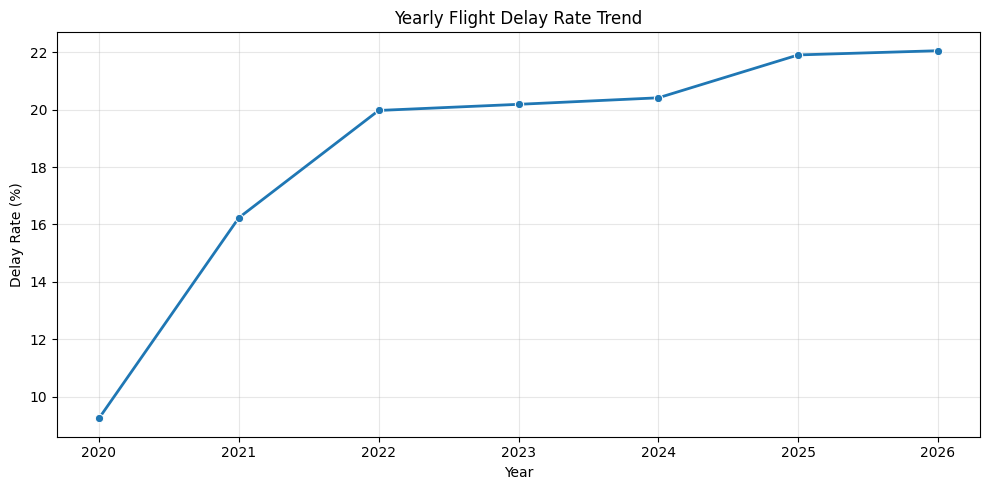

In [30]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_analysis,
    x="year",
    y="delay_rate",
    marker="o",
    linewidth=2
)

plt.title("Yearly Flight Delay Rate Trend")
plt.xlabel("Year")
plt.ylabel("Delay Rate (%)")
plt.xticks(yearly_analysis["year"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

YEARLY DELAY RATE - INTERPRETATION
---------------------------------------------
The highest delay rate was recorded in 2026.0 at 22.06%.
The lowest delay rate was recorded in 2020.0 at 9.24%.

KEY INSIGHTS
1. The delay rate changed from 9.24% in 2020.0 to 22.06% in 2026.0.
2. The difference between the highest and lowest yearly delay rates is 12.82 percentage points.
3. The delay rate increased between the first and last recorded years.


Monthly Flight Delay Rate

In [31]:
# Calculate monthly flight delay rates

monthly_analysis = df_clean.groupby("month").agg(
    total_flights=("arr_flights", "sum"),
    delayed_flights=("arr_del15", "sum")
).reset_index()

# Calculate delay rate
monthly_analysis["delay_rate"] = (
    monthly_analysis["delayed_flights"] /
    monthly_analysis["total_flights"]
) * 100

# Display results
print("MONTHLY FLIGHT DELAY ANALYSIS")
print(monthly_analysis.round(2).to_string(index=False))

MONTHLY FLIGHT DELAY ANALYSIS
 month  total_flights  delayed_flights  delay_rate
     1      2522367.0         454354.0       18.01
     2      2359471.0         411076.0       17.42
     3      2756058.0         496052.0       18.00
     4      2479382.0         437205.0       17.63
     5      2495473.0         494396.0       19.81
     6      2535681.0         599158.0       23.63
     7      2719691.0         671011.0       24.67
     8      2277188.0         460178.0       20.21
     9      2134101.0         320770.0       15.03
    10      2250484.0         344404.0       15.30
    11      2159678.0         329130.0       15.24
    12      2190985.0         449146.0       20.50


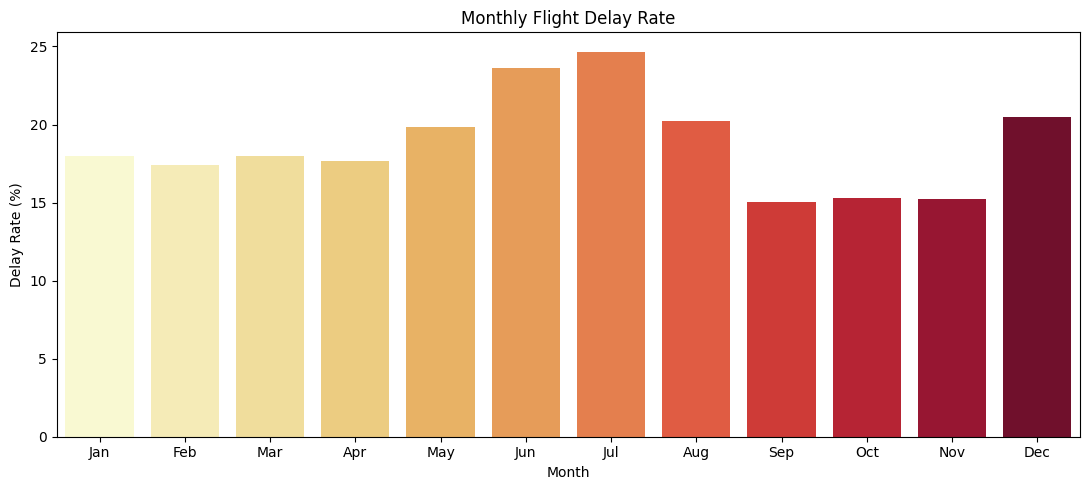

In [32]:
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(11, 5))

sns.barplot(
    data=monthly_analysis,
    x="month",
    y="delay_rate",
    hue="month",
    palette="YlOrRd",
    legend=False
)

plt.title("Monthly Flight Delay Rate")
plt.xlabel("Month")
plt.ylabel("Delay Rate (%)")

plt.xticks(
    ticks=range(12),
    labels=month_names
)

plt.tight_layout()
plt.show()

MONTHLY DELAY RATE - INTERPRETATION
---------------------------------------------
The highest delay rate was recorded in July at 24.67%.
The lowest delay rate was recorded in September at 15.03%.

KEY INSIGHTS
1. July has the highest delay rate among all months.
2. September has the lowest delay rate among all months.
3. The difference between the highest and lowest monthly delay rates is 9.64 percentage points.
4. The monthly comparison helps identify periods that may require better flight scheduling and planning.


Flight Delay Rate by Month and Year

In [33]:
# Group data by year and month

monthly_yearly = df_clean.groupby(
    ["year", "month"]
).agg(
    total_flights=("arr_flights", "sum"),
    delayed_flights=("arr_del15", "sum")
).reset_index()

# Calculate delay rate
monthly_yearly["delay_rate"] = (
    monthly_yearly["delayed_flights"] /
    monthly_yearly["total_flights"]
) * 100

# Create pivot table for heatmap
delay_heatmap = monthly_yearly.pivot(
    index="year",
    columns="month",
    values="delay_rate"
)

# Display results
print("MONTHLY AND YEARLY DELAY RATE")
print(delay_heatmap.round(2))

MONTHLY AND YEARLY DELAY RATE
month     1      2      3      4      5      6      7      8      9      10  \
year                                                                          
2020   13.73  14.95   8.41   2.98   3.97   6.31   8.24   7.60   6.03   8.24   
2021    9.86  13.82   9.68  10.27  12.60  22.33  23.47  21.45  13.39  16.76   
2022   17.50  18.52  20.53  20.95  20.57  22.75  22.38  21.18  16.04  15.38   
2023   21.91  18.87  23.10  22.37  17.92  26.43  27.68  21.09  18.57  15.16   
2024   22.84  15.67  20.69  19.00  25.88  24.23  28.37  22.96  15.47  13.02   
2025   18.26  20.46  19.09  19.51  23.82  27.30  27.71  22.09  16.69  20.30   
2026   19.55  18.66  23.05  19.59  20.84  24.69  27.10    NaN    NaN    NaN   

month     11     12  
year                 
2020    7.40  11.67  
2021   14.20  20.53  
2022   18.43  25.09  
2023   13.38  15.50  
2024   14.73  20.91  
2025   20.42  26.10  
2026     NaN    NaN  


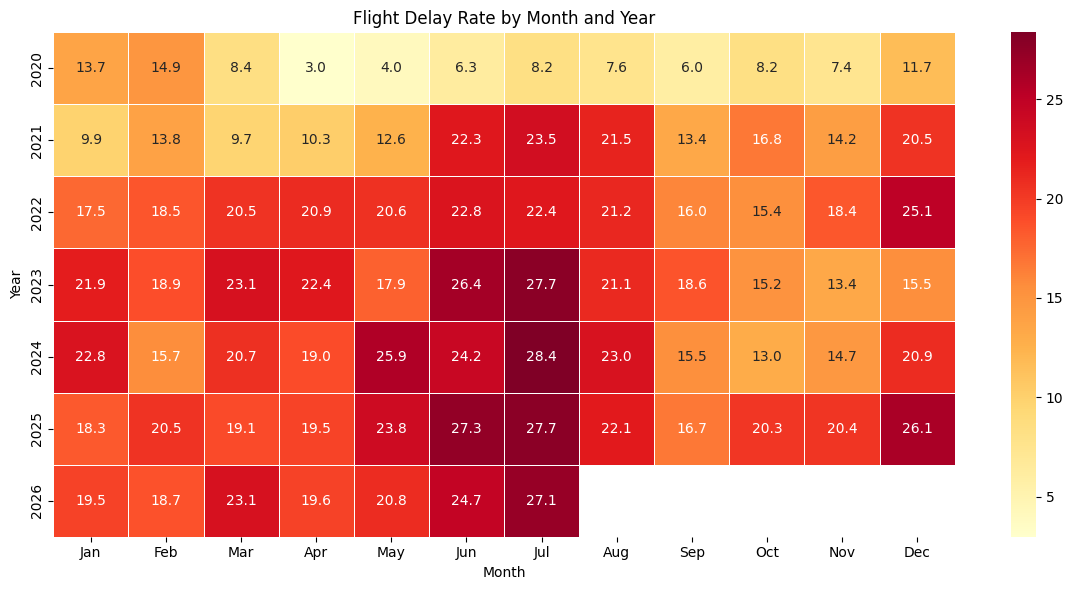

In [34]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    delay_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Flight Delay Rate by Month and Year")
plt.xlabel("Month")
plt.ylabel("Year")

plt.xticks(
    ticks=[i + 0.5 for i in range(12)],
    labels=month_names
)

plt.tight_layout()
plt.show()

YEAR-MONTH HEATMAP - INTERPRETATION
---------------------------------------------
The highest delay rate was recorded in July 2024.0 at 28.37%.
The lowest delay rate was recorded in April 2020.0 at 2.98%.

KEY INSIGHTS
1. July 2024.0 recorded the highest delay rate among the available month-year combinations.
2. April 2020.0 recorded the lowest delay rate among the available month-year combinations.
3. The heatmap highlights how delay rates vary across different months and years.
4. Darker cells indicate higher delay rates, while lighter cells indicate lower delay rates.


### Objective 2: Analyse airport and airline performance

Calculate airport delay rates

In [35]:
# Calculate flight delay statistics for each airport

airport_analysis = df_clean.groupby(
    ["airport", "airport_name"]
).agg(
    total_flights=("arr_flights", "sum"),
    delayed_flights=("arr_del15", "sum")
).reset_index()

# Calculate delay rate
airport_analysis["delay_rate"] = (
    airport_analysis["delayed_flights"] /
    airport_analysis["total_flights"]
) * 100

# Sort and select top 10 airports
top_airports = airport_analysis.sort_values(
    by="delay_rate",
    ascending=False
).head(10)

# Display results
print("TOP 10 AIRPORTS BY DELAY RATE")
print(top_airports.round(2).to_string(index=False))

TOP 10 AIRPORTS BY DELAY RATE
airport                                                 airport_name  total_flights  delayed_flights  delay_rate
    FLL Fort Lauderdale, FL: Fort Lauderdale-Hollywood International       560569.0         130689.0       23.31
    MCO                           Orlando, FL: Orlando International       955333.0         220258.0       23.06
    LAS                      Las Vegas, NV: Harry Reid International       729998.0         167385.0       22.93
    SFO               San Francisco, CA: San Francisco International       832715.0         184772.0       22.19
    EWR                     Newark, NJ: Newark Liberty International       832473.0         181945.0       21.86
    TPA                               Tampa, FL: Tampa International       476282.0         102967.0       21.62
    BOS                              Boston, MA: Logan International       819116.0         175461.0       21.42
    AUS                 Austin, TX: Austin - Bergstrom Internation

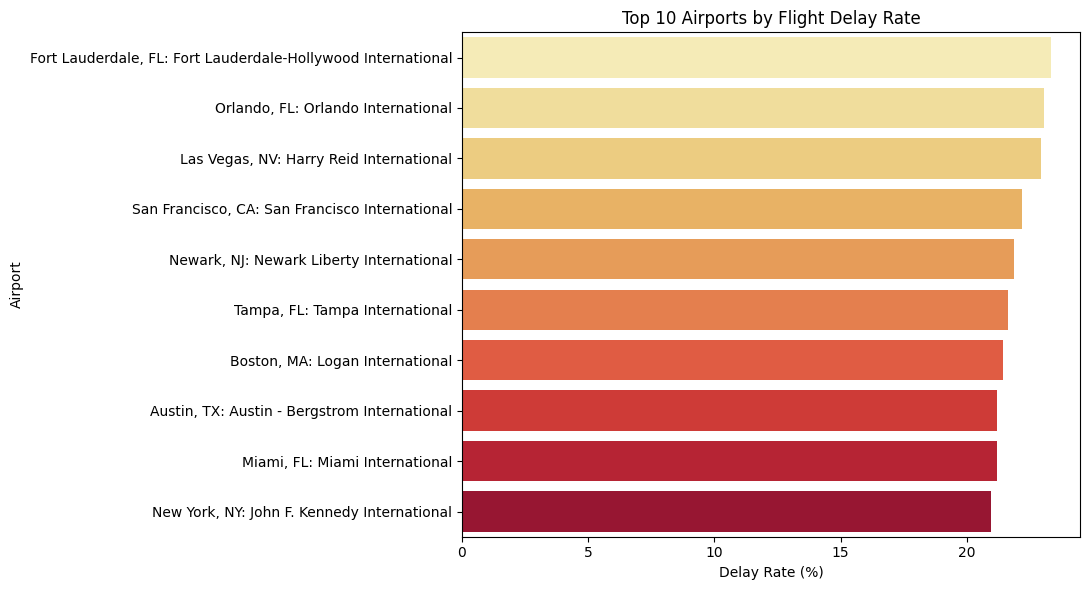

In [36]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_airports,
    x="delay_rate",
    y="airport_name",
    hue="airport_name",
    palette="YlOrRd",
    legend=False
)

plt.title("Top 10 Airports by Flight Delay Rate")
plt.xlabel("Delay Rate (%)")
plt.ylabel("Airport")

plt.tight_layout()
plt.show()

AIRPORT PERFORMANCE - INTERPRETATION
---------------------------------------------
Fort Lauderdale, FL: Fort Lauderdale-Hollywood International recorded the highest delay rate of 23.31%.
New York, NY: John F. Kennedy International recorded the lowest delay rate among the top 10 airports, at 20.95%.

KEY INSIGHTS
1. Fort Lauderdale, FL: Fort Lauderdale-Hollywood International has the highest delay rate among the top 10 airports.
2. It handled 560,569 flights, of which 130,689 were delayed.
3. The difference between the highest and lowest delay rates in the top 10 is 2.36 percentage points.


Top 10 Airlines by Flight Delay Rate

In [37]:
# Calculate flight delay statistics for each airline

airline_analysis = df_clean.groupby(
    ["carrier", "carrier_name"]
).agg(
    total_flights=("arr_flights", "sum"),
    delayed_flights=("arr_del15", "sum"),
    cancelled_flights=("arr_cancelled", "sum")
).reset_index()

# Calculate delay rate
airline_analysis["delay_rate"] = (
    airline_analysis["delayed_flights"] /
    airline_analysis["total_flights"]
) * 100

# Sort and select top 10 airlines
top_airlines = airline_analysis.sort_values(
    by="delay_rate",
    ascending=False
).head(10)

# Display results
print("TOP 10 AIRLINES BY DELAY RATE")
print(top_airlines.round(2).to_string(index=False))

TOP 10 AIRLINES BY DELAY RATE
carrier                              carrier_name  total_flights  delayed_flights  cancelled_flights  delay_rate
     F9                         Frontier Airlines       816057.0         221849.0            19076.0       27.19
     G4                             Allegiant Air       127765.0          33663.0             4871.0       26.35
     B6                           JetBlue Airways      1118459.0         290650.0            29721.0       25.99
     HA                 Hawaiian Airlines Network        38926.0           9610.0              322.0       24.69
     NK                           Spirit Airlines      1032482.0         239093.0            24278.0       23.16
     AA                 American Airlines Network      4451649.0         928655.0           108332.0       20.86
     G7   GoJet Airlines LLC d/b/a United Express       216782.0          44974.0             8653.0       20.75
     WN                        Southwest Airlines      4509075.0  

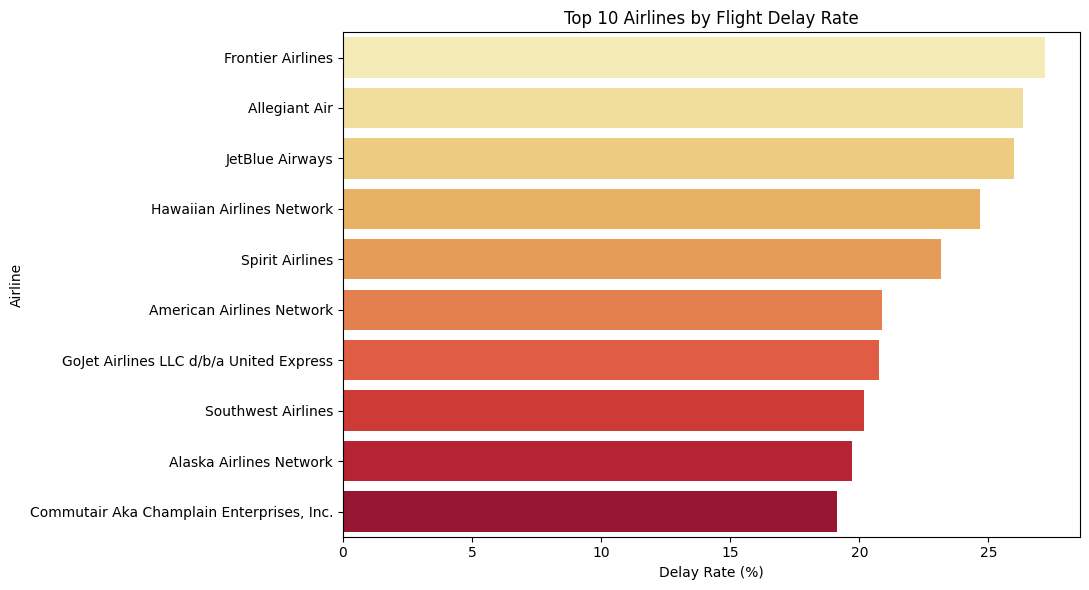

In [38]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_airlines,
    x="delay_rate",
    y="carrier_name",
    hue="carrier_name",
    palette="YlOrRd",
    legend=False
)

plt.title("Top 10 Airlines by Flight Delay Rate")
plt.xlabel("Delay Rate (%)")
plt.ylabel("Airline")

plt.tight_layout()
plt.show()

AIRLINE PERFORMANCE - INTERPRETATION
---------------------------------------------
Frontier Airlines recorded the highest delay rate of 27.19%.
Commutair Aka Champlain Enterprises, Inc. recorded the lowest delay rate among the top 10 airlines, at 19.12%.

KEY INSIGHTS
1. Frontier Airlines has the highest delay rate among the top 10 airlines.
2. It operated 816,057 flights, of which 221,849 were delayed.
3. The difference between the highest and lowest delay rates in the top 10 is 8.06 percentage points.


### Objective 3: Identify the major causes of flight delays

* carrier_delay	Delays caused by the airline
* weather_delay	Delays caused by weather conditions
* nas_delay	Delays caused by the National Airspace System
* security_delay	Delays caused by security issues
* late_aircraft_delay	Delays caused by late-arriving aircraft

Calculate total delay minutes by cause

In [53]:

# Calculate total number of delays by cause

cause_count_analysis = pd.DataFrame({
    "Delay Cause": [
        "Carrier",
        "Weather",
        "NAS",
        "Security",
        "Late Aircraft"
    ],
    "Total Delays": [
        df_clean["carrier_ct"].sum(),
        df_clean["weather_ct"].sum(),
        df_clean["nas_ct"].sum(),
        df_clean["security_ct"].sum(),
        df_clean["late_aircraft_ct"].sum()
    ]
})

# Sort from highest to lowest
cause_count_analysis = cause_count_analysis.sort_values(
    by="Total Delays",
    ascending=False
)

# Display results
cause_count_analysis


,Delay Cause,Total Delays
4,Late Aircraft,1877404.11
0,Carrier,1721543.65
2,NAS,1650101.85
1,Weather,203032.28
3,Security,14753.90


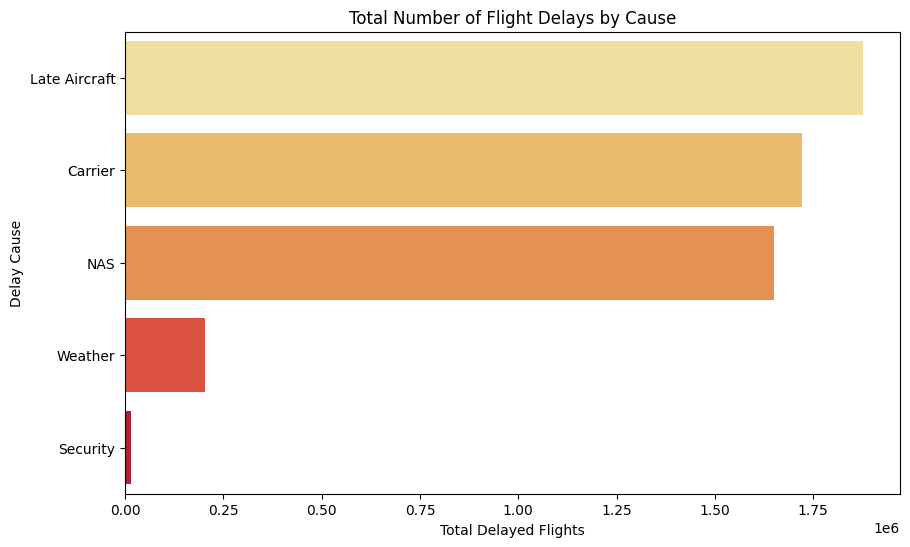

In [54]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=cause_count_analysis,
    x="Total Delays",
    y="Delay Cause",
    hue="Delay Cause",
    palette="YlOrRd",
    legend=False
)

plt.title("Total Number of Flight Delays by Cause")
plt.xlabel("Total Delayed Flights")
plt.ylabel("Delay Cause")

plt.show()


INTERPRETATION
----------------------------------------
1. Late Aircraft recorded the highest number of delays, with 1,877,404.
2. Security recorded the lowest number of delays, with 14,754.

KEY INSIGHTS
----------------------------------------
Late Aircraft: 1,877,404 delays
Carrier: 1,721,544 delays
NAS: 1,650,102 delays
Weather: 203,032 delays
Security: 14,754 delays


### Objective 4: Analyse the Relationship Between Delays, Cancellations, and Diversions

In [42]:
# Calculate total flight statistics

total_flights = df_clean["arr_flights"].sum()

total_delayed = df_clean["arr_del15"].sum()

total_cancelled = df_clean["arr_cancelled"].sum()

total_diverted = df_clean["arr_diverted"].sum()

# Calculate flights without delays
total_ontime = total_flights - total_delayed

# Create summary DataFrame
flight_status = pd.DataFrame({
    "Flight Status": [
        "On Time",
        "Delayed",
        "Cancelled",
        "Diverted"
    ],
    "Total Flights": [
        total_ontime,
        total_delayed,
        total_cancelled,
        total_diverted
    ]
})

flight_status

,Flight Status,Total Flights
0,On Time,23413679.0
1,Delayed,5466880.0
2,Cancelled,651041.0
3,Diverted,72111.0


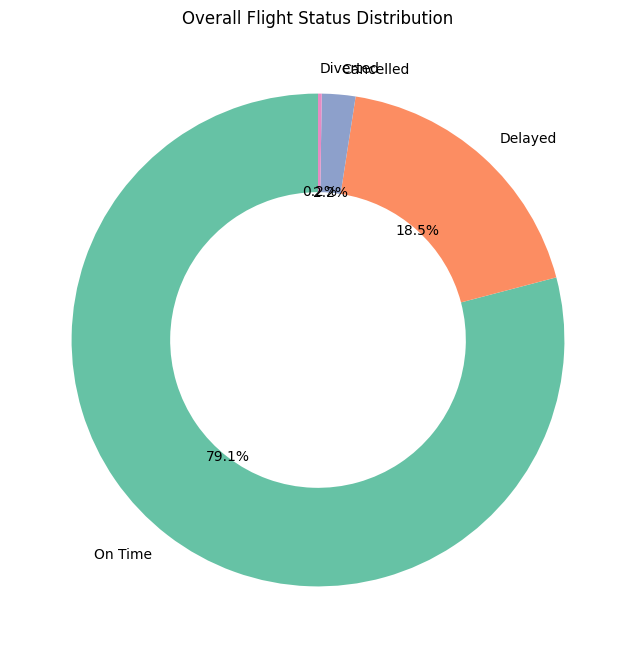

In [43]:
# What is the overall distribution of delayed, cancelled, diverted, and remaining flights?
plt.figure(figsize=(8, 8))

plt.pie(
    flight_status["Total Flights"],
    labels=flight_status["Flight Status"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4},
    colors=sns.color_palette("Set2", 4)
)

plt.title("Overall Flight Status Distribution")

plt.show()

INTERPRETATION
------------------------------------------
1. On Time: 23,413,679 flights (81.07%).
KEY INSIGHTS
2. Delayed: 5,466,880 flights (18.93%).

KEY INSIGHTS
* Cancelled: 651,041 flights (2.25%).
* Diverted: 72,111 flights (0.25%).

1. On Time has the highest flight count.
2. Diverted has the lowest flight count.
3. A total of 5,466,880 flights experienced delays of 15 minutes or more.


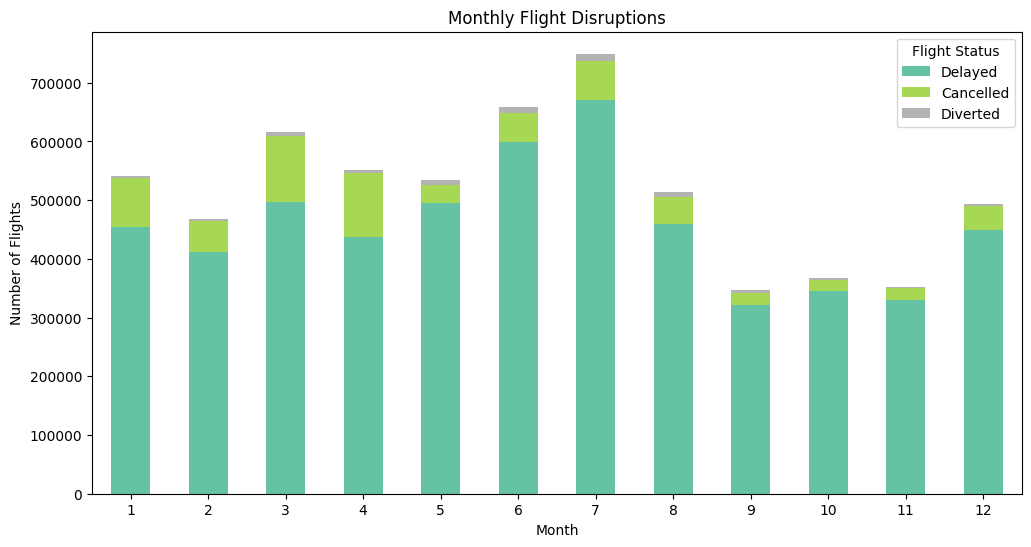

In [44]:
# Calculate monthly flight disruptions

monthly_disruptions = df_clean.groupby("month").agg(
    Delayed=("arr_del15", "sum"),
    Cancelled=("arr_cancelled", "sum"),
    Diverted=("arr_diverted", "sum")
)

# Create stacked bar chart

monthly_disruptions.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="Set2"
)

plt.title("Monthly Flight Disruptions")
plt.xlabel("Month")
plt.ylabel("Number of Flights")
plt.xticks(rotation=0)
plt.legend(title="Flight Status")

plt.show()

INTERPRETATION
-------------------------------------------
* Delayed: Highest number recorded in Month 7, with 671,011 flights.

KEY INSIGHTS
* Cancelled: Highest number recorded in Month 3, with 113,118 flights.
* Diverted: Highest number recorded in Month 7, with 12,631 flights.

Delayed flights were highest in Month 7.
Cancelled flights were highest in Month 3.
Diverted flights were highest in Month 7.


Relationship between delays and cancellations

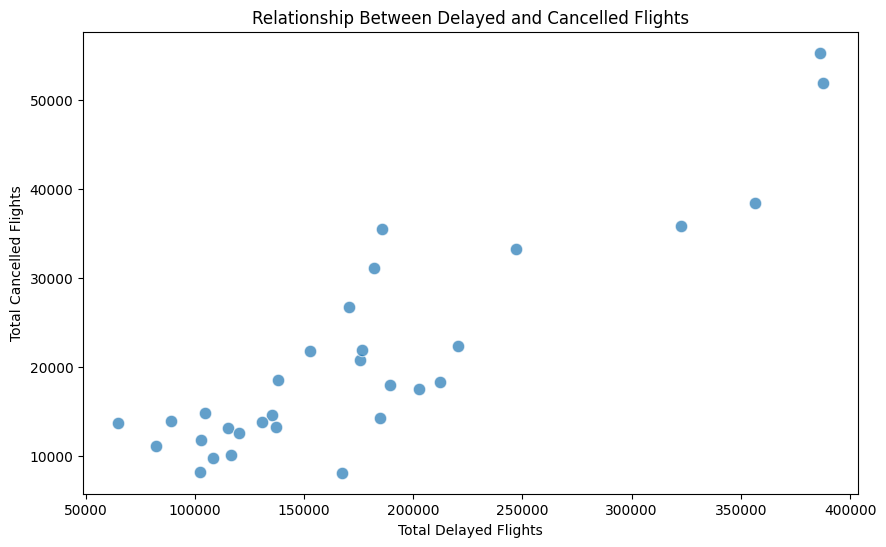

In [45]:
# Calculate airport-level delays and cancellations

airport_disruptions = df_clean.groupby(
    ["airport", "airport_name"]
).agg(
    Delayed=("arr_del15", "sum"),
    Cancelled=("arr_cancelled", "sum")
).reset_index()

# Create scatter plot

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=airport_disruptions,
    x="Delayed",
    y="Cancelled",
    s=80,
    alpha=0.7
)

plt.title("Relationship Between Delayed and Cancelled Flights")
plt.xlabel("Total Delayed Flights")
plt.ylabel("Total Cancelled Flights")

plt.show()

INTERPRETATION
-------------------------------------------
The correlation between delayed and cancelled flights across airports is 0.89.
There is a strong positive relationship.
1. Dallas/Fort Worth, TX: Dallas/Fort Worth International has the highest number of cancelled flights.
2. The correlation between delayed and cancelled flights is 0.89.
3. Airports with higher flight disruption counts can be examined further for operational improvements.


### Objective 5: Analyse total flight delay duration by cause

In [46]:
# Select delay duration columns

delay_duration = df_clean[
    [
        "year",
        "carrier_delay",
        "weather_delay",
        "nas_delay",
        "security_delay",
        "late_aircraft_delay"
    ]
]

delay_duration.head()

,year,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2026,24403.0,6656.0,19423.0,18.0,46239.0
1,2026,454.0,0.0,423.0,0.0,132.0
2,2026,1642.0,162.0,1790.0,0.0,2661.0
3,2026,1685.0,0.0,936.0,0.0,1246.0
4,2026,1324.0,103.0,2692.0,0.0,2278.0


In [47]:
# Calculate average delay duration by cause

average_delay = delay_duration[
    [
        "carrier_delay",
        "weather_delay",
        "nas_delay",
        "security_delay",
        "late_aircraft_delay"
    ]
].mean()

# Convert into a DataFrame
average_delay = average_delay.reset_index()

average_delay.columns = [
    "Delay Cause",
    "Average Delay Minutes"
]

# Sort from highest to lowest
average_delay = average_delay.sort_values(
    by="Average Delay Minutes",
    ascending=False
)

average_delay

,Delay Cause,Average Delay Minutes
4,late_aircraft_delay,5330.346090
0,carrier_delay,4922.463960
2,nas_delay,2968.670903
1,weather_delay,799.267010
3,security_delay,24.866251


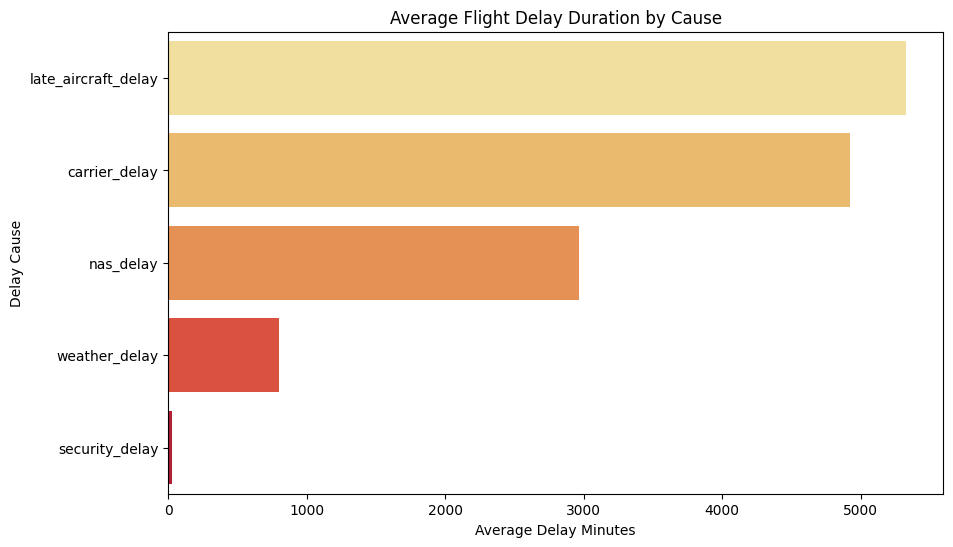

In [48]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=average_delay,
    x="Average Delay Minutes",
    y="Delay Cause",
    hue="Delay Cause",
    palette="YlOrRd",
    legend=False
)

plt.title("Average Flight Delay Duration by Cause")
plt.xlabel("Average Delay Minutes")
plt.ylabel("Delay Cause")

plt.show()

INTERPRETATION
---------------------------------------------
1. late_aircraft_delay has the highest average delay duration of 5330.35 minutes per record.
2. security_delay has the lowest average delay duration of 24.87 minutes per record.

KEY INSIGHTS
1. late_aircraft_delay: 5330.35 average delay minutes per record.
2. carrier_delay: 4922.46 average delay minutes per record.
3. nas_delay: 2968.67 average delay minutes per record.
4. weather_delay: 799.27 average delay minutes per record.
5. security_delay: 24.87 average delay minutes per record.
